# real ECG+PPG: is a simple model faithful to ptt?

In [1]:
import numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import mechlib

torch.manual_seed(0); np.random.seed(0)
dev = torch.device("cpu"); ECG, PPG = 0, 1

d = mechlib.load_mini("../data/vitaldb_mini.npz"); fs = int(d["fs"])
Xtr = mechlib.normalize(d["Xtr"][:, :, [ECG, PPG]]); ytr = d["ytr"]
Xte = mechlib.normalize(d["Xte"][:, :, [ECG, PPG]]); yte = d["yte"]; gte = d["gte"]

print("Xtr", Xtr.shape, " -- (segments, timesteps, [ecg, ppg])")
print("ytr", ytr.shape, " -- (segments, [sbp, dbp])")
print("fs ", fs, "Hz  ->", Xtr.shape[1] / fs, "sec / segment")

Xtr (4000, 1250, 2)  -- (segments, timesteps, [ecg, ppg])
ytr (4000, 2)  -- (segments, [sbp, dbp])
fs  125 Hz  -> 10.0 sec / segment


## the label we'll probe for: ptt, detected from the raw signal

In [2]:
ptt = mechlib.compute_ptt(Xte, fs, ecg_pos=ECG, ppg_pos=PPG)
print("ptt", ptt.shape, " -- one value per test segment (seconds), nan where undetectable")
print(f"detected in {np.isfinite(ptt).mean()*100:.0f}% of segments")

ptt (1200,)  -- one value per test segment (seconds), nan where undetectable
detected in 99% of segments


## a simple mlp: input shape -> features -> bp

In [3]:
class MLP(nn.Module):
    def __init__(s, D=64):
        super().__init__()
        s.body = nn.Sequential(nn.AvgPool1d(10), nn.Flatten(),              # 1250 -> 125 / channel
                               nn.Linear(2 * (Xtr.shape[1] // 10), 128), nn.ReLU(),
                               nn.Linear(128, D), nn.ReLU())
        s.head = nn.Linear(D, 2)
    def features(s, x): return s.body(x.transpose(1, 2))    # (n, D) -- what we'll probe
    def forward(s, x): return s.head(s.features(x))          # (n, 2) -- [sbp, dbp]

net = MLP()
x_demo = torch.tensor(Xtr[:4])
print("input   ", tuple(x_demo.shape))
print("features", tuple(net.features(x_demo).shape))
print("output  ", tuple(net(x_demo).shape))

input    (4, 1250, 2)
features (4, 64)
output   (4, 2)


## train, watch the loss curve

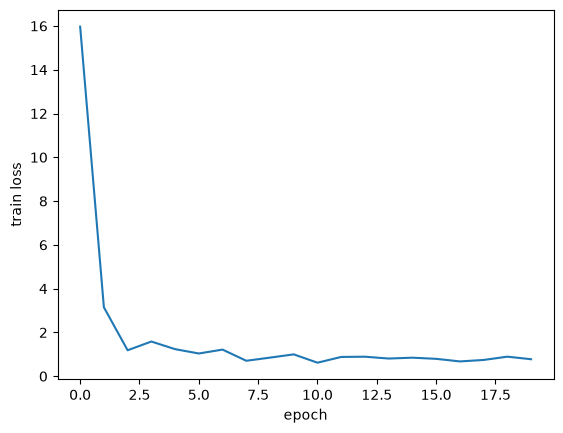

In [4]:
opt = torch.optim.Adam(net.parameters(), 2e-3)
Xt = torch.tensor(Xtr); yt = torch.tensor(ytr); var = torch.tensor(ytr.var(0))

losses = []
for ep in range(20):
    perm = torch.randperm(len(Xt))
    for i in range(0, len(Xt), 128):
        b = perm[i:i + 128]
        loss = (((net(Xt[b]) - yt[b]) ** 2) / var).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    losses.append(loss.item())
net.eval()

plt.plot(losses); plt.xlabel("epoch"); plt.ylabel("train loss"); plt.show()

In [5]:
pred = mechlib.predict(net, Xte, dev)
mae = mechlib.calibrated_mae(pred, yte, gte, K=3)
print("calibrated DBP MAE:", round(float(mae[1]), 1), "mmHg")

calibrated DBP MAE: 8.0 mmHg


## linear probe: is ptt decodable from what the model learned?

In [6]:
def get_features(model, X, bs=512):
    model.eval(); out = []
    with torch.no_grad():
        for s in range(0, len(X), bs):
            out.append(model.features(torch.tensor(X[s:s + bs])).numpy())
    return np.concatenate(out)

feats = get_features(net, Xte)
print("feats", feats.shape, " -- (segments, 64) -- the model's internal representation")

probe_r2 = mechlib.linear_probe(feats, ptt)
print("linear probe R2 (decode ptt from feats):", round(probe_r2, 2))

feats (1200, 64)  -- (segments, 64) -- the model's internal representation
linear probe R2 (decode ptt from feats): 0.01


## but is ptt actually *used*? shift ptt, watch predicted bp

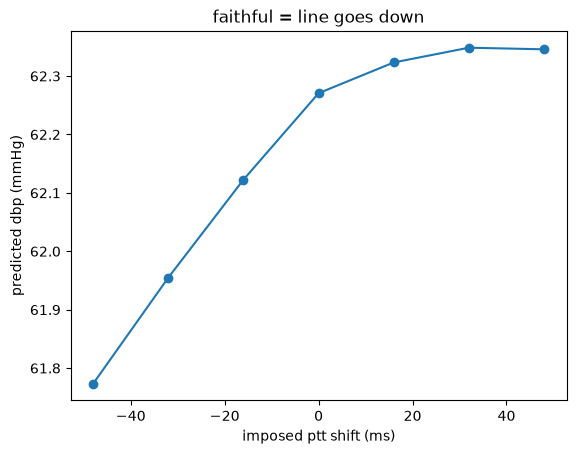

In [7]:
au = mechlib.causal_ptt_audit(net, Xte, fs, dev, ppg_pos=PPG)

plt.plot(au["shift_ms"], au["dbp"]["curve"], "-o")
plt.xlabel("imposed ptt shift (ms)"); plt.ylabel("predicted dbp (mmHg)")
plt.title("faithful = line goes down"); plt.show()

## decodable is not the same as used
ptt is linearly decodable from the model's features (probe R² above), yet the curve above doesn't reliably slope down when we push ptt up. the model can carry ptt information internally without actually routing its prediction through it.